# Entrega 2 — Análise Exploratória e Preparação dos Dados

**Projeto:** Predição de HbA1c alterada a partir dos dados da Pesquisa Nacional de Saúde (PNS) 2013
**Grupo:** Gabriela Tucunduva, Luisa de Matos e Maria Luisa Latta

A análise exploratória usa **somente `X_treino` e `y_treino`**. O conjunto de teste é separado antes da EDA e fica trancado.

> **Nota metodológica:** HbA1c ≥ 6,5% é usada como critério laboratorial para construir o alvo. Isso, sozinho, não equivale a um diagnóstico clínico de diabetes.

## 1. Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, f1_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Carregamento dos dados

In [2]:
CAMINHO_DADOS = "https://github.com/tucunduvas/diabetes_risk_prediction/raw/refs/heads/main/data/exames-PNS-2013-final.xlsx"
df_original = pd.read_excel(CAMINHO_DADOS)

print("Dimensões da base original:", df_original.shape)

Dimensões da base original: (8952, 509)


## 3. Limpeza linha a linha e definição do alvo

A função `limpar(df)` só faz operações que olham **uma linha por vez**. Os códigos abaixo foram conferidos no dicionário da PNS:

- `Q030 == 3`: respondeu **"Não"** à pergunta "algum médico já lhe deu o diagnóstico de diabetes?". Ficam só pessoas sem diagnóstico prévio.
- `P005 != 1`: sai quem respondeu **"Sim"** à pergunta sobre gravidez atual.
- `Z034`: resultado da hemoglobina glicosilada (HbA1c, em %). No dicionário, `.` significa "amostra inadequada" e vira ausente. Sem resultado não há alvo, então essas linhas saem.
- `hba1c_alterada = 1` quando `Z034 ≥ 6,5`.

In [3]:
def limpar(base):
    dados = base[(base["Q030"] == 3) & (base["P005"] != 1)].copy()
    dados["Z034"] = pd.to_numeric(dados["Z034"], errors="coerce")
    dados = dados.dropna(subset=["Z034"])
    dados["hba1c_alterada"] = (dados["Z034"] >= 6.5).astype(int)
    return dados

df = limpar(df_original)
print("Dimensões após a limpeza:", df.shape)
print("Linhas removidas:", len(df_original) - len(df))

Dimensões após a limpeza: (6832, 510)
Linhas removidas: 2120


## 4. Escolha das variáveis e separação treino/teste

Foram escolhidas 10 variáveis explicativas: demográficas (sexo, idade), medidas autorreferidas (peso, altura), uma condição de saúde (hipertensão) e hábitos de vida (alimentação e exercício). A separação é estratificada, com `random_state=42`.

`Z034` (a própria HbA1c) **fica fora de X**, pois é o que define o alvo. `Q030` e `P005` só são usadas no filtro de `limpar`.

In [4]:
variaveis_numericas = ["Z002", "P00101", "P00401", "P006", "P018", "P020", "P025"]
variaveis_categoricas = ["Z001", "Q002", "P034"]

X = df[variaveis_numericas + variaveis_categoricas]
y = df["hba1c_alterada"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Treino:", X_treino.shape[0], "| Teste (trancado):", X_teste.shape[0])
print(f"Classe positiva no treino: {y_treino.mean():.2%}")

Treino: 5465 | Teste (trancado): 1367
Classe positiva no treino: 3.79%


In [5]:
# Nomes legíveis (conferidos no dicionário) só para os títulos dos gráficos
nomes = {
    "Z002": "idade (anos)", "P00101": "peso (kg)", "P00401": "altura (cm)",
    "P006": "dias/semana com feijão", "P018": "dias/semana com frutas",
    "P020": "dias/semana com refrigerante", "P025": "dias/semana com doces",
    "Z001": "sexo", "Q002": "hipertensão diagnosticada", "P034": "exercício nos últimos 3 meses",
}
rotulos = {
    "Z001": {1: "Masculino", 2: "Feminino"},
    "Q002": {1: "Sim", 2: "Só na gravidez", 3: "Não"},
    "P034": {1: "Sim", 2: "Não"},
}
continuas = ["Z002", "P00101", "P00401"]
dias = ["P006", "P018", "P020", "P025"]

## 5. Pergunta 1 — Como o alvo se distribui?

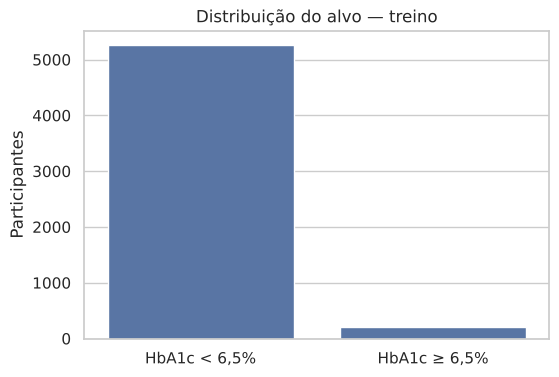

,quantidade,percentual
"HbA1c < 6,5%",5258,96.21
"HbA1c ≥ 6,5%",207,3.79


In [6]:
contagem = y_treino.value_counts().sort_index()
percentual = y_treino.value_counts(normalize=True).sort_index() * 100
rotulos_alvo = ["HbA1c < 6,5%", "HbA1c ≥ 6,5%"]

plt.figure(figsize=(6, 4))
sns.barplot(x=rotulos_alvo, y=contagem.values)
plt.title("Distribuição do alvo — treino")
plt.ylabel("Participantes")
plt.show()

display(pd.DataFrame({"quantidade": contagem.values, "percentual": percentual.round(2).values}, index=rotulos_alvo))

**Observação:** o alvo é muito desbalanceado: 5.258 participantes (96,2%) com HbA1c < 6,5% e só 207 (3,8%) com HbA1c ≥ 6,5%. Um modelo que sempre responde "não" acertaria 96,2% e não encontraria ninguém com a HbA1c alterada.

**Decisão:** manter `stratify=y` no split (já usado). Manter a métrica da E1: **recall da classe positiva**, porque o projeto é de rastreamento e deixar de sinalizar quem tem HbA1c elevada é o erro mais caro. Acompanhar também precisão, F1 da classe positiva e F1-macro; a acurácia fica só como informação complementar. Testar `class_weight` na E3, e não aplicar oversampling nem SMOTE no dataset inteiro.

## 6. Pergunta 2 — Onde faltam dados?

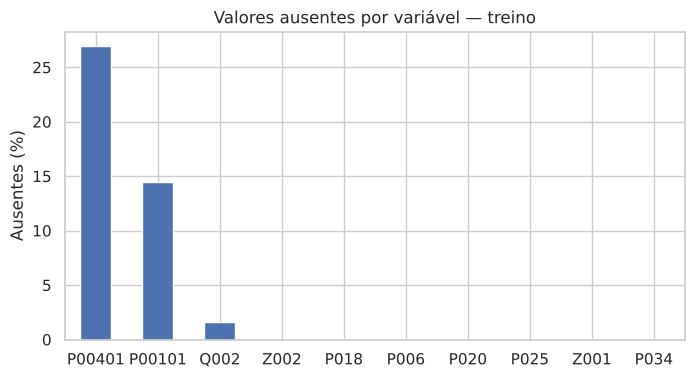

,% ausente
P00401,26.94
P00101,14.51
Q002,1.57
Z002,0.00
P018,0.00
P006,0.00
P020,0.00
P025,0.00
Z001,0.00
P034,0.00


,P00101,P00401
hba1c_alterada,,
0,14.2,26.8
1,21.7,31.4


In [7]:
ausentes = X_treino.isna().mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
ausentes.plot(kind="bar")
plt.title("Valores ausentes por variável — treino")
plt.ylabel("Ausentes (%)")
plt.xticks(rotation=0)
plt.show()
display(ausentes.round(2).to_frame("% ausente"))

# Quem tem HbA1c alterada deixa peso e altura em branco com mais frequência?
display(X_treino[["P00101", "P00401"]].isna().groupby(y_treino).mean().mul(100).round(1))

**Observação:** a altura (`P00401`) tem 26,9% de ausentes e o peso (`P00101`) tem 14,5%. A hipertensão (`Q002`) tem 1,6%. As demais não têm ausentes no treino. Entre quem tem HbA1c alterada, o peso fica em branco em 21,7% dos casos, contra 14,2% no outro grupo. A diferença vem de só 207 pessoas, mas indica que o vazio pode carregar informação.

**Decisão:** peso e altura (entre 5% e 50%): imputar pela **mediana** e adicionar **indicador de ausência** (`add_indicator=True`). Hipertensão (abaixo de 5%): imputar pela **moda**. Nenhum `dropna()` nas linhas, porque o treino não encolhe e a API também vai receber campos vazios. As colunas sem ausentes ganham o mesmo imputer por segurança, já que o usuário da API pode deixar qualquer campo em branco.

Os valores `.` do dicionário ("não aplicável"/"amostra inadequada") já chegam como ausentes. Nas colunas escolhidas não há códigos como 99 ou 999: os dias por semana vão de 0 a 7, o peso de 32 a 211 kg e a altura de 120 a 202 cm. Por isso `limpar` não precisa converter nenhum valor em NaN.

## 7. Pergunta 3 — Como cada variável se distribui?

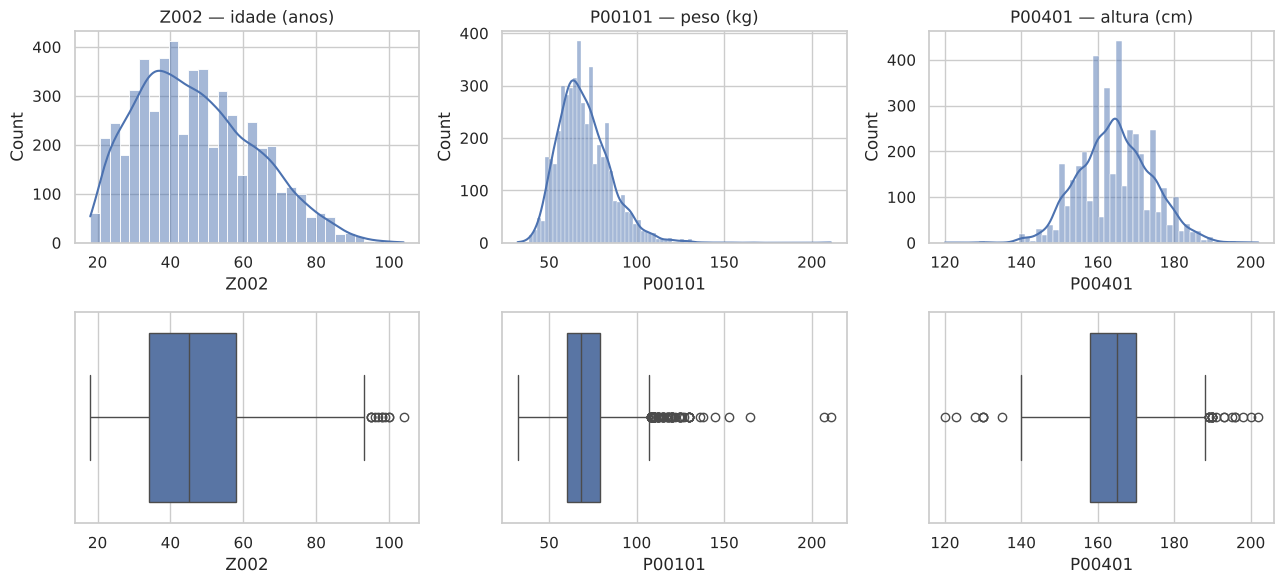

,Z002,P00101,P00401
count,5465.0,4672.0,3993.0
mean,46.9,70.1,164.5
std,16.1,15.0,9.4
min,18.0,32.0,120.0
25%,34.0,60.0,158.0
50%,45.0,68.0,165.0
75%,58.0,79.0,170.0
max,104.0,211.0,202.0


In [8]:
fig, eixos = plt.subplots(2, 3, figsize=(13, 6))
for i, col in enumerate(continuas):
    sns.histplot(X_treino[col].dropna(), kde=True, ax=eixos[0, i])
    eixos[0, i].set_title(f"{col} — {nomes[col]}")
    sns.boxplot(x=X_treino[col].dropna(), ax=eixos[1, i])
plt.tight_layout()
plt.show()

display(X_treino[continuas].describe().round(1))

**Observação (idade):** vai de 18 a 104 anos, com mediana de 45. A cauda à direita é leve: só 11 pessoas aparecem como pontos fora do boxplot e 3 têm 100 anos ou mais. Todos os valores são possíveis.

**Decisão (idade):** nenhum valor é erro, então nada vira NaN. Manter e padronizar com `StandardScaler`.

**Observação (peso):** vai de 32 a 211 kg, com mediana de 68 e cauda longa à direita (83 pontos fora do boxplot). É uma pergunta autorreferida, mas os valores altos são plausíveis.

**Decisão (peso):** os valores altos são reais, então ficam. Imputar pela mediana, que não é puxada pela cauda, e padronizar. Testar o log do peso na E3.

**Observação (altura):** vai de 120 a 202 cm, com mediana de 165 e forma simétrica. Há 28 pontos fora do boxplot, todos plausíveis.

**Decisão (altura):** manter. Mediana, indicador de ausência e `StandardScaler`.

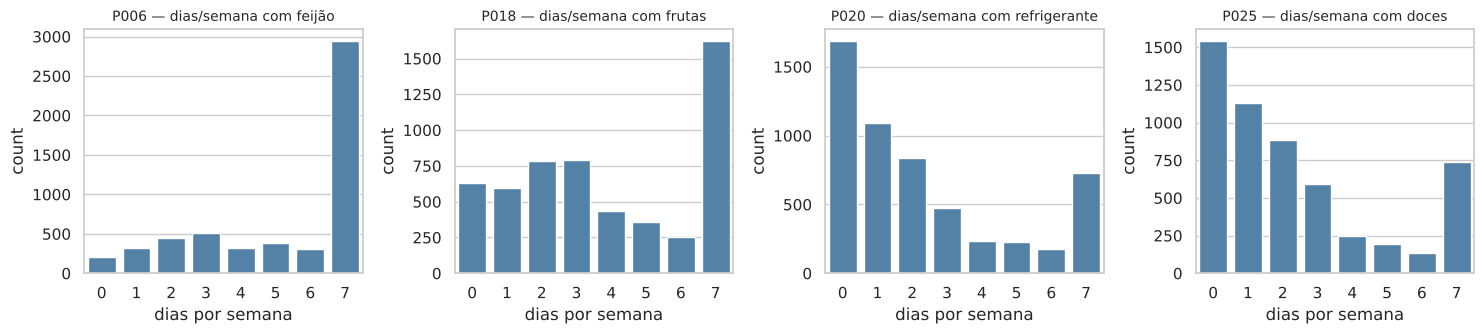

In [9]:
fig, eixos = plt.subplots(1, 4, figsize=(15, 3.5))
for i, col in enumerate(dias):
    sns.countplot(x=X_treino[col].dropna().astype(int), ax=eixos[i], color="steelblue")
    eixos[i].set_title(f"{col} — {nomes[col]}", fontsize=10)
    eixos[i].set_xlabel("dias por semana")
plt.tight_layout()
plt.show()

**Observação:** as quatro variáveis só têm valores de 0 a 7, sem códigos estranhos. Feijão: 53,9% marcaram 7 dias. Frutas: 29,7% marcaram 7 e 11,5% marcaram 0. Refrigerante: 30,9% marcaram 0 e 13,4% marcaram 7. Doces: 28,2% marcaram 0 e 13,5% marcaram 7.

**Decisão:** tratar como **numéricas**, pois a ordem importa (0 a 7 dias). Mediana e `StandardScaler`. Não há outliers a tratar: todo valor entre 0 e 7 é válido.

Z001 {'Feminino': 59.2, 'Masculino': 40.8}
Q002 {'Não': 74.4, 'Sim': 22.3, 'Só na gravidez': 1.7, 'Ausente': 1.6}
P034 {'Não': 70.6, 'Sim': 29.4}


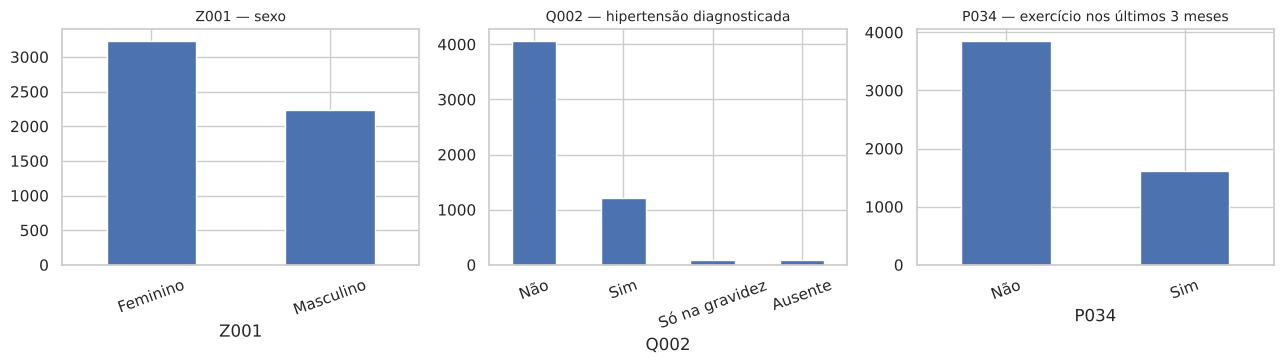

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
for i, col in enumerate(variaveis_categoricas):
    categorias = X_treino[col].map(rotulos[col]).fillna("Ausente")
    categorias.value_counts().plot(kind="bar", ax=eixos[i])
    eixos[i].set_title(f"{col} — {nomes[col]}", fontsize=10)
    eixos[i].tick_params(axis="x", rotation=20)
    print(col, categorias.value_counts(normalize=True).mul(100).round(1).to_dict())
plt.tight_layout()
plt.show()

**Observação:** sexo: 59,2% feminino e 40,8% masculino. Hipertensão: 74,4% "Não", 22,3% "Sim", 1,7% "só na gravidez" e 1,6% ausentes. Exercício: 70,6% não praticaram e 29,4% praticaram.

**Decisão:** as três são **categóricas**. Os números 1, 2 e 3 são códigos, não quantidades. Moda para os vazios e `OneHotEncoder(handle_unknown="ignore")`. A categoria "só na gravidez" é pequena (93 pessoas), mas fica: o encoder lida com ela e com categorias novas na API.

## 8. Pergunta 4 — O que se relaciona com o alvo?

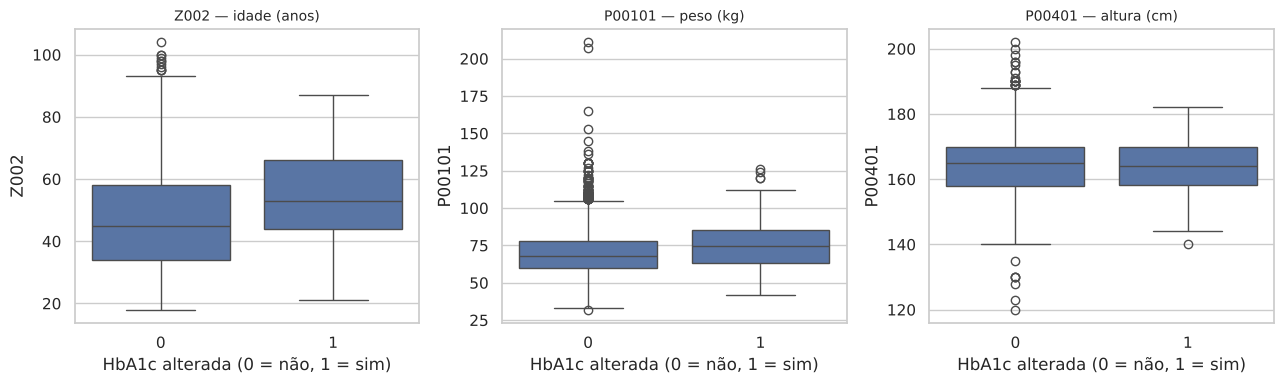

,Z002,P00101,P00401
hba1c_alterada,,,
0,45.0,68.0,165.0
1,53.0,74.5,164.0


In [11]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
for i, col in enumerate(continuas):
    sns.boxplot(x=y_treino, y=X_treino[col], ax=eixos[i])
    eixos[i].set_title(f"{col} — {nomes[col]}", fontsize=10)
    eixos[i].set_xlabel("HbA1c alterada (0 = não, 1 = sim)")
plt.tight_layout()
plt.show()

display(X_treino[continuas].groupby(y_treino).median())

**Observação:** quem tem HbA1c alterada é mais velho (mediana de 53 anos contra 45) e mais pesado (74,5 kg contra 68). A altura é praticamente igual nos dois grupos (164 cm contra 165).

**Decisão:** manter idade e peso, que mostram diferença clara. Manter também a altura, que não separa as classes sozinha mas acompanha o peso. Nenhuma variável é removida olhando gráfico: a seleção será conferida em validação cruzada, nunca com o teste.

,P006,P018,P020,P025
hba1c_alterada,,,,
0,5.21,3.83,2.28,2.33
1,5.26,3.73,2.16,1.86


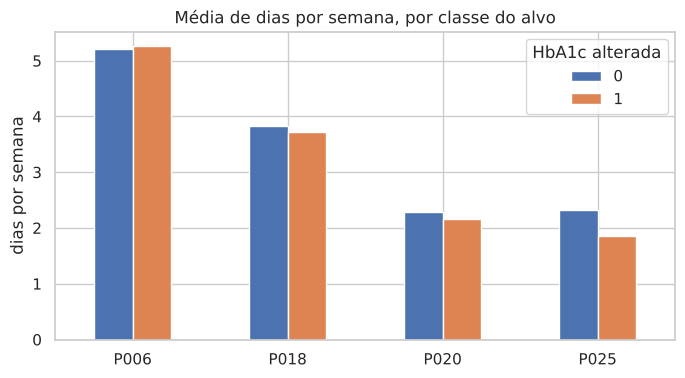

In [12]:
medias_dias = X_treino[dias].groupby(y_treino).mean().round(2)
display(medias_dias)

medias_dias.T.plot(kind="bar", figsize=(8, 4))
plt.title("Média de dias por semana, por classe do alvo")
plt.ylabel("dias por semana")
plt.xticks(rotation=0)
plt.legend(title="HbA1c alterada")
plt.show()

**Observação:** feijão (5,21 contra 5,26), frutas (3,83 contra 3,73) e refrigerante (2,28 contra 2,16) quase não mudam entre as classes. Doces mostra a maior diferença: 2,33 dias na classe 0 contra 1,86 na classe 1, ou seja, quem tem HbA1c alterada relata comer **menos** doces.

**Decisão:** manter as quatro por enquanto e deixar a validação cruzada da E3 dizer se ajudam. O resultado dos doces é contraintuitivo, e a associação não implica causa: pode ser acaso ou mudança de hábito de quem já se sente mal. Isso não é motivo para descartar nem para interpretar como efeito.

Z001 {'Feminino': 3.9, 'Masculino': 3.6}
Q002 {'Ausente': 2.3, 'Não': 3.2, 'Sim': 5.8, 'Só na gravidez': 3.2}
P034 {'Não': 4.4, 'Sim': 2.4}


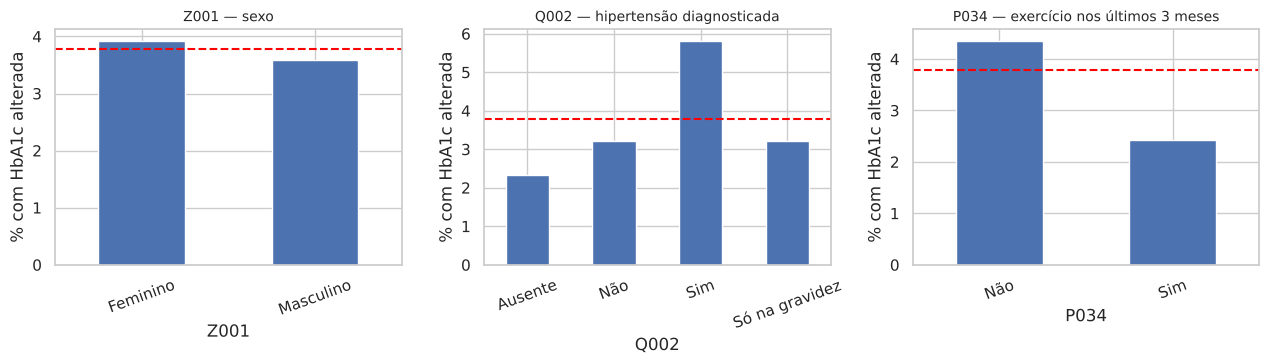

In [13]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
for i, col in enumerate(variaveis_categoricas):
    taxa = y_treino.groupby(X_treino[col].map(rotulos[col]).fillna("Ausente")).mean().mul(100)
    taxa.plot(kind="bar", ax=eixos[i])
    eixos[i].axhline(y_treino.mean() * 100, color="red", linestyle="--")
    eixos[i].set_title(f"{col} — {nomes[col]}", fontsize=10)
    eixos[i].set_ylabel("% com HbA1c alterada")
    eixos[i].tick_params(axis="x", rotation=20)
    print(col, taxa.round(1).to_dict())
plt.tight_layout()
plt.show()

**Observação:** a linha vermelha é a taxa geral (3,8%). Quem tem hipertensão diagnosticada tem HbA1c alterada em 5,8% dos casos, contra 3,2% de quem não tem. Quem pratica exercício tem 2,4%, contra 4,4% de quem não pratica. Sexo quase não muda (masculino 3,6%, feminino 3,9%). As categorias "só na gravidez" (3,2%, 93 pessoas) e "ausente" (2,3%, 86 pessoas) são pequenas demais para tirar conclusão.

**Decisão:** manter as três. Hipertensão e exercício mostram diferença; sexo mostra pouca, mas é uma variável demográfica básica e a validação cruzada diz se ajuda.

**Vazamento:** nenhuma variável de X é medida depois do alvo. `Z034` ficou fora de X e `Q030` e `P005` só entram no filtro de `limpar`.

## 9. Pergunta 5 — Há colunas redundantes?

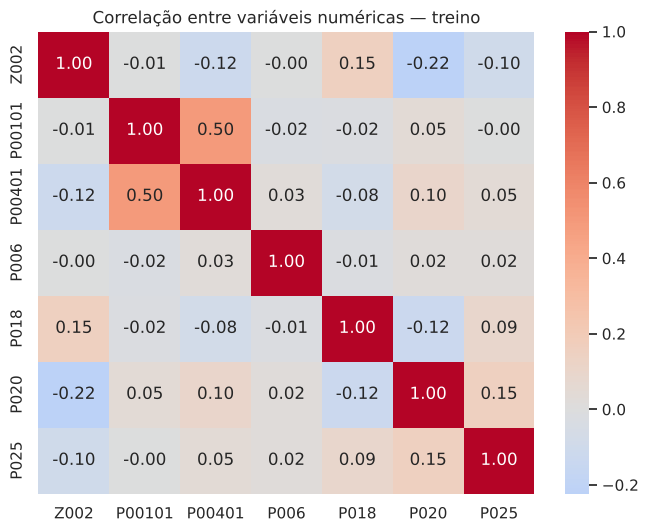

Maior |r| entre colunas diferentes: 0.50


In [14]:
correlacao = X_treino[variaveis_numericas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre variáveis numéricas — treino")
plt.show()

maior = correlacao.where(~np.eye(len(correlacao), dtype=bool)).abs().max().max()
print(f"Maior |r| entre colunas diferentes: {maior:.2f}")

**Observação:** a maior correlação é entre peso e altura (r = 0,50), o que é esperado. Nenhum par chega perto de |r| > 0,9.

**Decisão:** nenhuma coluna é removida por redundância.

## 10. Tabela de decisões

| Coluna | O que é | Tipo | Achado na EDA | Decisão | Onde |
|---|---|---|---|---|---|
| `Z002` | idade | numérica | 18 a 104 anos, sem ausentes | mediana + `StandardScaler` | pipeline |
| `P00101` | peso (kg) | numérica | 14,5% ausente; cauda à direita (até 211 kg), valores plausíveis | mediana + indicador + `StandardScaler` | pipeline |
| `P00401` | altura (cm) | numérica | 26,9% ausente; 120 a 202 cm, plausíveis | mediana + indicador + `StandardScaler` | pipeline |
| `P006`, `P018`, `P020`, `P025` | dias/semana (feijão, frutas, refrigerante, doces) | numérica (0 a 7) | sem ausentes, sem códigos especiais | mediana + `StandardScaler` | pipeline |
| `Z001` | sexo | categórica | 2 categorias, sem ausentes | moda + one-hot (`ignore`) | pipeline |
| `Q002` | hipertensão diagnosticada | categórica | 3 categorias; 1,6% ausente; "só na gravidez" com 93 pessoas | moda + one-hot (`ignore`) | pipeline |
| `P034` | exercício nos últimos 3 meses | categórica | 2 categorias, sem ausentes | moda + one-hot (`ignore`) | pipeline |
| `Q030` | diagnóstico prévio de diabetes | filtro | só quem respondeu "Não" (3) entra | filtro e não vai para X | `limpar(df)` |
| `P005` | gravidez atual | filtro | quem respondeu "Sim" (1) sai | filtro e não vai para X | `limpar(df)` |
| `Z034` | HbA1c (%) | define o alvo | vaza o alvo (é o próprio alvo) | vira `hba1c_alterada`; fora de X | `limpar(df)` + seleção de X |
| demais 496 colunas | outros módulos da PNS | não selecionadas | fora do escopo desta entrega | ficam de fora | seleção de X |

## 11. Pré-processador com `ColumnTransformer`

- **Numéricas:** imputação pela mediana (com indicador de ausência) e `StandardScaler`.
- **Categóricas:** imputação pela moda e `OneHotEncoder(handle_unknown="ignore")`.
- Coluna que não está em nenhuma lista fica de fora (`remainder="drop"`).

O pré-processador ainda **não foi treinado**: ele só aprende (`fit`) dentro do `Pipeline`, usando o treino de cada fold.

In [15]:
num = Pipeline([
    ("imp", SimpleImputer(strategy="median", add_indicator=True)),
    ("esc", StandardScaler()),
])
cat = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

pre = ColumnTransformer(
    [("num", num, variaveis_numericas), ("cat", cat, variaveis_categoricas)],
    remainder="drop",
    sparse_threshold=0,
)

## 12. Teste de sanidade do pré-processador

In [16]:
Xt = pre.fit_transform(X_treino)

print("Linhas antes:", X_treino.shape[0], "| depois:", Xt.shape[0])
print("Colunas depois:", Xt.shape[1])
print("NaN depois:", np.isnan(Xt).sum())
print(list(pre.get_feature_names_out()))

assert Xt.shape[0] == X_treino.shape[0]
assert np.isnan(Xt).sum() == 0

Linhas antes: 5465 | depois: 5465
Colunas depois: 16
NaN depois: 0
['num__Z002', 'num__P00101', 'num__P00401', 'num__P006', 'num__P018', 'num__P020', 'num__P025', 'num__missingindicator_P00101', 'num__missingindicator_P00401', 'cat__Z001_1.0', 'cat__Z001_2.0', 'cat__Q002_1.0', 'cat__Q002_2.0', 'cat__Q002_3.0', 'cat__P034_1.0', 'cat__P034_2.0']


**Resultado:** 5.465 linhas antes e depois, nenhum NaN. A matriz tem 16 colunas: 7 numéricas, 2 indicadores de ausência (peso e altura, as únicas colunas com ausentes) e 7 colunas de one-hot (sexo 2, hipertensão 3, exercício 2).

## 13. Validação cruzada e comparação com o baseline

Mesma validação e mesmas métricas do baseline da E1 (`StratifiedKFold` com 5 dobras, `shuffle=True` e `random_state=42`), sempre no treino e com o pipeline completo: o pré-processador é treinado de novo em cada fold. O teste não é usado.

Entram três modelos: o baseline (`Dummy`, sempre "não"), a regressão logística simples e a mesma regressão com `class_weight="balanced"`. A terceira linha serve só para mostrar se o pipeline consegue aprender; a escolha formal de modelo e de balanceamento fica para a E3.

In [17]:
modelos = {
    "Dummy (sempre 'não')": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(max_iter=1000),
    "Regressão logística (class_weight)": LogisticRegression(max_iter=1000, class_weight="balanced"),
}

# mesma validação e mesmas métricas do baseline da E1
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "acuracia": "accuracy",
    "recall_positivo": "recall",
    "precisao_positivo": make_scorer(precision_score, zero_division=0),
    "f1_positivo": make_scorer(f1_score, zero_division=0),
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
}

linhas = {}
for nome, modelo in modelos.items():
    pipe = Pipeline([("pre", pre), ("modelo", modelo)])
    s = cross_validate(pipe, X_treino, y_treino, cv=cv, scoring=scoring)
    linhas[nome] = {m: s[f"test_{m}"].mean() for m in scoring}

resultados = pd.DataFrame(linhas).T
display(resultados.round(4))

,acuracia,recall_positivo,precisao_positivo,f1_positivo,f1_macro,balanced_accuracy
Dummy (sempre 'não'),0.9621,0.0000,0.0000,0.0000,0.4903,0.5000
Regressão logística,0.9619,0.0000,0.0000,0.0000,0.4903,0.4999
Regressão logística (class_weight),0.6337,0.6479,0.0648,0.1178,0.4432,0.6405


## 14. Conclusão

**Resultado da validação cruzada:** o `Dummy` e a regressão logística simples ficam empatados: recall de 0, F1-macro de 0,49 e acurácia balanceada de 0,50. A acurácia de 96,2% só reflete a classe majoritária. Com o desbalanceamento, a regressão logística comum aprende a responder sempre "não". Com `class_weight="balanced"`, o recall da classe positiva sobe para 0,65 e a acurácia balanceada para 0,64, então o pipeline aprende alguma coisa.

**Leitura:** na métrica principal definida na E1 (recall da classe positiva), o pipeline supera o baseline: 0,65 contra 0. O custo é a precisão, de apenas 0,06: a grande maioria dos alertas é falso positivo. Por isso o F1-macro (0,44) fica abaixo do baseline (0,49) e a acurácia cai para 0,63. O desafio da E3 é o que a E1 já previa: manter um bom recall sem uma quantidade inviável de falsos positivos.

**Resumo das decisões:**
- **Alvo:** 3,8% de classe positiva; split estratificado e métricas que não sejam acurácia.
- **Ausentes:** peso (14,5%) e altura (26,9%) com mediana e indicador; hipertensão (1,6%) com moda; nenhuma linha removida.
- **Distribuições:** nenhum valor impossível; os valores altos de peso e idade são reais e foram mantidos.
- **Relação com o alvo:** idade, peso, hipertensão e exercício mostram diferença entre as classes; as demais serão avaliadas por validação cruzada. Nenhuma associação foi interpretada como causa.
- **Redundância:** maior |r| = 0,50 (peso × altura); nenhuma coluna removida.
- **Pré-processamento:** o `ColumnTransformer` roda sem erro, não deixa NaN e funciona em validação cruzada; tudo que é aprendido fica dentro do pipeline.

**Limitações:** os dados são da PNS 2013 e o ponto de corte de HbA1c é um critério analítico, não um diagnóstico. Peso e altura são autorreferidos. O peso amostral (`peso_lab`), ponto em aberto da E1, não foi usado. Só há 207 casos positivos no treino, então as diferenças entre classes devem ser lidas com cautela. O teste continua trancado para a avaliação final.